# Supplementary Figure — PCA of optotagged cells

Principal component analysis and K-means clustering of electrophysiological features, highlighting the optotagged `ChAT`, `VGLuT`, and `cGAT` populations.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from kneed import KneeLocator
from sklearn import metrics
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler

## Setup and data loading

In [2]:
# Locate the input files whether Jupyter starts in the repository root
# or in the notebook directory.
project_candidates = (Path.cwd(), *Path.cwd().parents)
project_root = next(
    (path for path in project_candidates if (path / "data" / "tag" / "df_VEH.pkl").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate data/tag/df_VEH.pkl from the current directory.")

data_path = project_root / "data" / "tag"
feature_data = pd.read_pickle(data_path / "df_VEH.pkl")

# The NumPy files use one-based row indices; convert them to zero-based indices.
optotagged_indices = {
    "ChAT": np.asarray(np.load(data_path / "CHAT.npy")[0], dtype=int) - 1,
    "VGLuT": np.asarray(np.load(data_path / "Vglut.npy")[0], dtype=int) - 1,
    "cGAT": np.asarray(np.load(data_path / "Vgat.npy")[0], dtype=int) - 1,
}
optotagged_colors = {
    "ChAT": "#B085D6",
    "VGLuT": "#84155F",
    "cGAT": "#619A8F",
}
optotagged_order = ["ChAT", "VGLuT", "cGAT"]

# Validate all selections and ensure that no cell has multiple labels.
assigned_indices = np.concatenate(list(optotagged_indices.values()))
if not np.all(np.isin(assigned_indices, feature_data.index)):
    raise IndexError("At least one optotagged index is absent from the feature table.")
if len(np.unique(assigned_indices)) != len(assigned_indices):
    raise ValueError("Overlapping optotagged cell indices were detected.")

for population in optotagged_order:
    print(f"{population}: {len(optotagged_indices[population])} cells")

ChAT: 10 cells
VGLuT: 40 cells
cGAT: 16 cells


In [3]:
# Keep the same 22 complete numerical features used in the original notebook.
metadata_columns = ["animal", "ID"]
features = feature_data.drop(columns=metadata_columns)
if features.isna().any().any():
    raise ValueError("The PCA feature matrix contains missing values.")

scaler = StandardScaler()
standardized_features = scaler.fit_transform(features)
print(f"Feature matrix: {standardized_features.shape[0]} cells × {standardized_features.shape[1]} features")

Feature matrix: 431 cells × 22 features


## Select the number of principal components

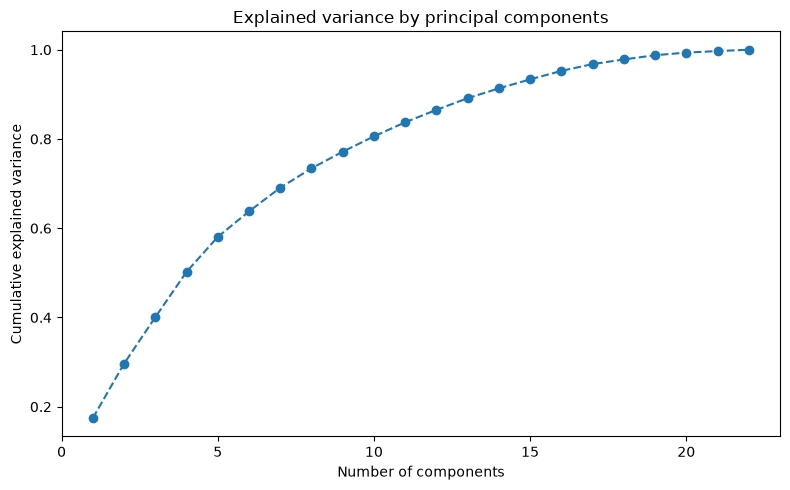

Number of principal components retained: 6


In [4]:
full_pca = PCA()
full_pca.fit(standardized_features)
cumulative_variance = np.cumsum(full_pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    linestyle="--",
)
ax.set(
    xlabel="Number of components",
    ylabel="Cumulative explained variance",
    title="Explained variance by principal components",
    xlim=(0, len(cumulative_variance) + 1),
)
plt.tight_layout()
plt.show()

# Preserve the original scree-bend calculation.
variance_percent = 100 * full_pca.explained_variance_ratio_
reference_line = variance_percent[0] + (
    (variance_percent[-1] - variance_percent[0])
    / (variance_percent.size - 1)
    * np.arange(variance_percent.size)
)
retained_components = int(np.argmin(variance_percent - reference_line) + 1)
print(f"Number of principal components retained: {retained_components}")

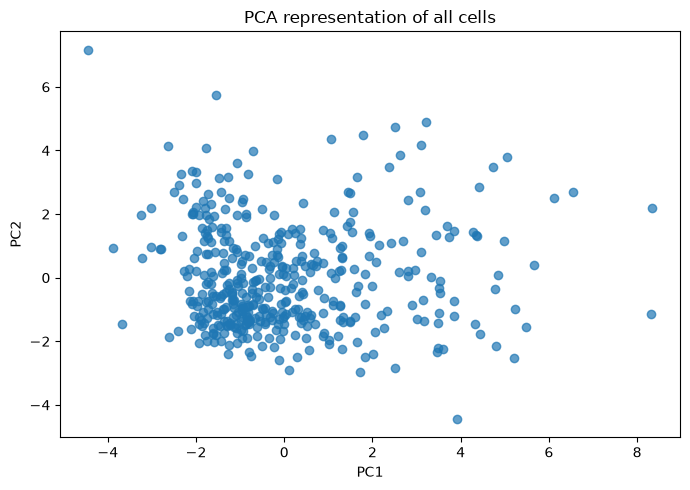

,Component,Highest-loading feature
0,PC1,firingRateISI
1,PC2,firingRateGiniCoeff
2,PC3,peakVoltage_expFitLengthConstant
3,PC4,acg_c
4,PC5,acg_tau_decay
5,PC6,acg_d


In [5]:
# Fit the retained PCA representation once and reuse it downstream.
pca = PCA(n_components=retained_components)
pca_scores = pca.fit_transform(standardized_features)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(pca_scores[:, 0], pca_scores[:, 1], color="tab:blue", alpha=0.7)
ax.set(xlabel="PC1", ylabel="PC2", title="PCA representation of all cells")
plt.tight_layout()
plt.show()

most_important_indices = np.argmax(np.abs(pca.components_), axis=1)
important_features = pd.DataFrame(
    {
        "Component": [f"PC{i + 1}" for i in range(retained_components)],
        "Highest-loading feature": features.columns[most_important_indices],
    }
)
important_features

## t-SNE representation

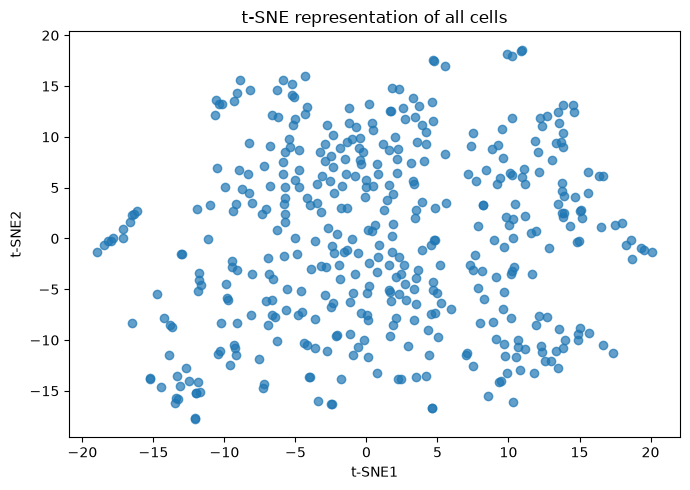

In [6]:
# Preserve the original deterministic t-SNE parameters.
tsne = TSNE(
    n_components=2,
    verbose=0,
    perplexity=40,
    random_state=42,
    max_iter=5000,
    learning_rate=200,
    init="random",
    n_jobs=-1,
)
tsne_scores = tsne.fit_transform(standardized_features)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(tsne_scores[:, 0], tsne_scores[:, 1], color="tab:blue", alpha=0.7)
ax.set(xlabel="t-SNE1", ylabel="t-SNE2", title="t-SNE representation of all cells")
plt.tight_layout()
plt.show()

## Evaluate the number of K-means clusters

In [7]:
# Preserve the original K-means initialization and random seed.
cluster_range_wcss = range(1, 20)
wcss = []
for cluster_count in cluster_range_wcss:
    model = KMeans(
        n_clusters=cluster_count,
        init="k-means++",
        random_state=42,
        n_init=100,
    )
    model.fit(pca_scores)
    wcss.append(model.inertia_)

knee = KneeLocator(cluster_range_wcss, wcss, curve="convex", direction="decreasing")

cluster_range_metrics = range(2, 11)
silhouette_scores = []
cosine_scores = []
for cluster_count in cluster_range_metrics:
    model = KMeans(
        n_clusters=cluster_count,
        init="k-means++",
        random_state=42,
        n_init=100,
    )
    cluster_labels = model.fit_predict(pca_scores)

    within_cluster_similarity = []
    for cluster in np.unique(cluster_labels):
        indices = np.flatnonzero(cluster_labels == cluster)
        cluster_mean = features.iloc[indices].mean(axis=0).to_numpy()[None, :]
        for index in indices:
            cell_features = features.iloc[index].to_numpy()[None, :]
            within_cluster_similarity.append(
                cosine_similarity(cell_features, cluster_mean)[0, 0]
            )

    cosine_scores.append(np.mean(within_cluster_similarity))
    silhouette_scores.append(
        metrics.silhouette_score(pca_scores, cluster_labels, metric="euclidean")
    )

print(f"Elbow selected by KneeLocator: {knee.elbow} clusters")

Elbow selected by KneeLocator: 6 clusters


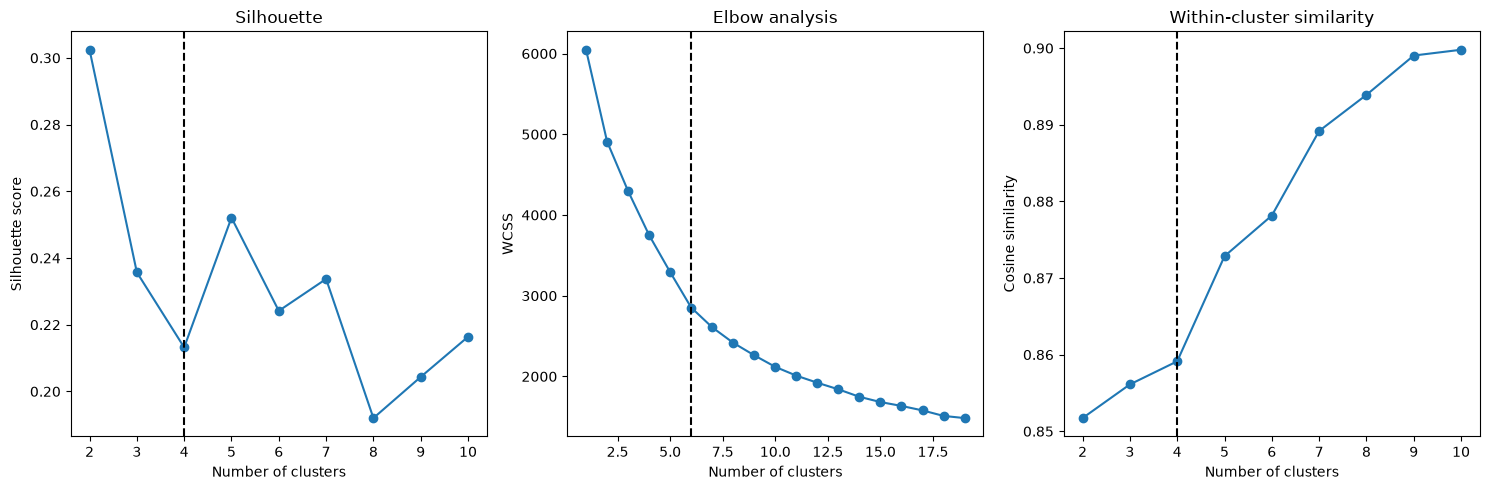

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].plot(list(cluster_range_metrics), silhouette_scores, "o-")
axes[0].set(xlabel="Number of clusters", ylabel="Silhouette score", title="Silhouette")
axes[0].axvline(4, color="black", linestyle="--")

axes[1].plot(list(cluster_range_wcss), wcss, "o-")
axes[1].set(xlabel="Number of clusters", ylabel="WCSS", title="Elbow analysis")
axes[1].axvline(knee.elbow, color="black", linestyle="--")

axes[2].plot(list(cluster_range_metrics), cosine_scores, "o-")
axes[2].set(xlabel="Number of clusters", ylabel="Cosine similarity", title="Within-cluster similarity")
axes[2].axvline(4, color="black", linestyle="--")

plt.tight_layout()
plt.show()

## Four-cluster PCA solution and optotagged populations

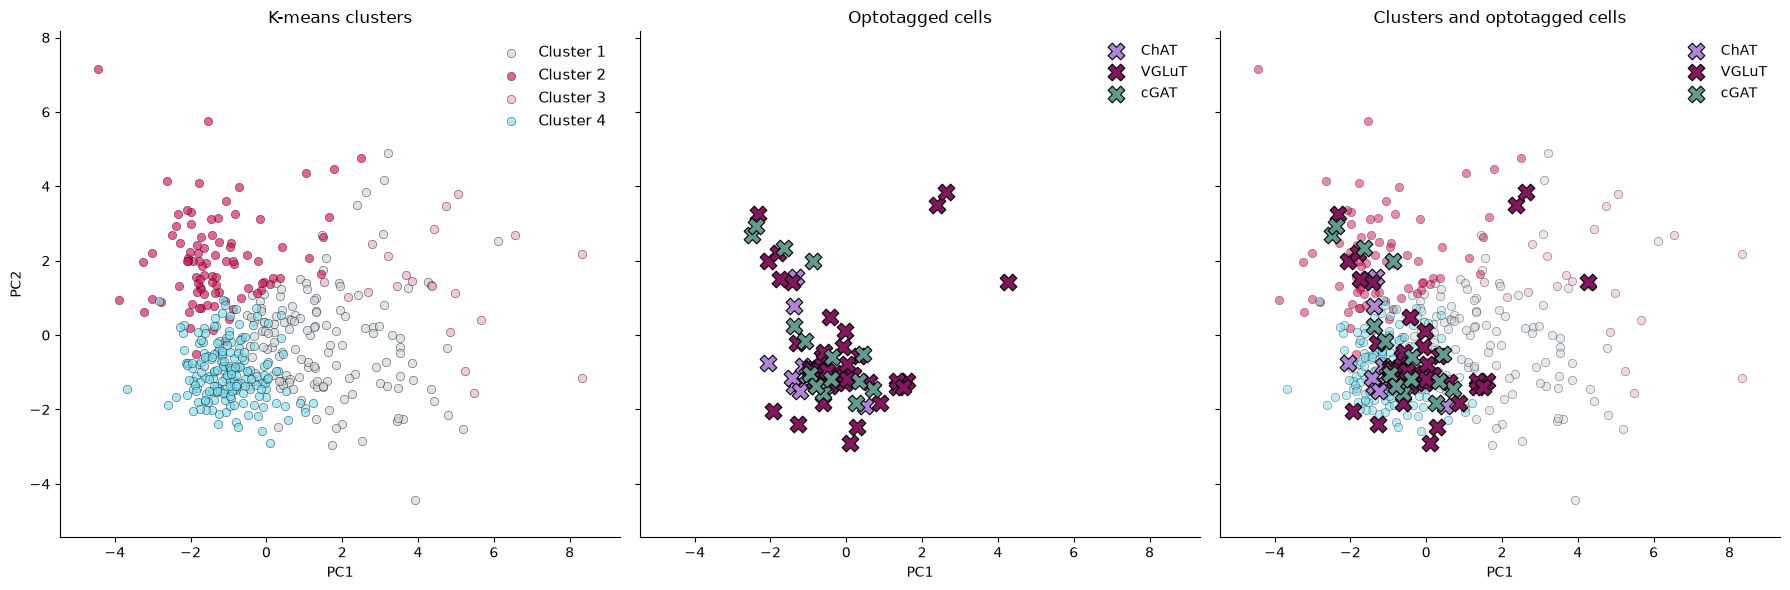

In [9]:
# The final figure preserves the original four-cluster solution.
number_of_clusters = 4
kmeans = KMeans(
    n_clusters=number_of_clusters,
    init="k-means++",
    random_state=42,
    n_init=100,
)
cluster_labels = kmeans.fit_predict(pca_scores)

cluster_colors = ["#ced4da", "#D81159", "#efa6c9", "#7bdff2"]
x_limits = (pca_scores[:, 0].min() - 1, pca_scores[:, 0].max() + 1)
y_limits = (pca_scores[:, 1].min() - 1, pca_scores[:, 1].max() + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# Panel 1: all cells colored by K-means cluster.
for cluster in range(number_of_clusters):
    mask = cluster_labels == cluster
    axes[0].scatter(
        pca_scores[mask, 0],
        pca_scores[mask, 1],
        color=cluster_colors[cluster],
        edgecolor="black",
        linewidth=0.4,
        alpha=0.65,
        label=f"Cluster {cluster + 1}",
    )
axes[0].set_title("K-means clusters")
axes[0].set_ylabel("PC2")
axes[0].legend(fontsize=11, frameon=False)

# Panel 2: only the three optotagged populations.
for population in optotagged_order:
    indices = optotagged_indices[population]
    axes[1].scatter(
        pca_scores[indices, 0],
        pca_scores[indices, 1],
        marker="X",
        s=144,
        color=optotagged_colors[population],
        edgecolor="black",
        linewidth=0.8,
        label=population,
    )
axes[1].set_title("Optotagged cells")
axes[1].legend(frameon=False)

# Panel 3: cluster background with the optotagged populations overlaid.
for cluster in range(number_of_clusters):
    mask = cluster_labels == cluster
    axes[2].scatter(
        pca_scores[mask, 0],
        pca_scores[mask, 1],
        color=cluster_colors[cluster],
        edgecolor="black",
        linewidth=0.4,
        alpha=0.5,
    )
for population in optotagged_order:
    indices = optotagged_indices[population]
    axes[2].scatter(
        pca_scores[indices, 0],
        pca_scores[indices, 1],
        marker="X",
        s=144,
        color=optotagged_colors[population],
        edgecolor="black",
        linewidth=0.8,
        label=population,
    )
axes[2].set_title("Clusters and optotagged cells")
axes[2].legend(frameon=False)

for ax in axes:
    ax.set_xlim(x_limits)
    ax.set_ylim(y_limits)
    ax.set_xlabel("PC1")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Optotagged-cell cluster membership

In [10]:
membership_rows = []
for population in optotagged_order:
    population_clusters = cluster_labels[optotagged_indices[population]] + 1
    for cluster in range(1, number_of_clusters + 1):
        membership_rows.append(
            {
                "Population": population,
                "Cluster": cluster,
                "Cells": int(np.count_nonzero(population_clusters == cluster)),
            }
        )

cluster_membership = pd.DataFrame(membership_rows)
cluster_membership.pivot(index="Population", columns="Cluster", values="Cells").loc[optotagged_order]

Cluster,1,2,3,4
Population,,,,
ChAT,0,2,0,8
VGLuT,16,5,0,19
cGAT,3,5,0,8
